This notebook builds a quarterly macro–financial dataset starting from raw data downloaded from FRED (Federal Reserve Economic Data) and Yahoo Finance through the Python libraries fredapi and yfinance.

All series are transformed into log returns and resampled to quarterly frequency to ensure stationarity and comparability across variables.

The dataset includes key macroeconomic indicators — such as GDP, industrial production, unemployment rate, inflation, exchange rate, and personal consumption — together with financial market variables like the U.S. Dollar Index (DXY), S&P 500, and Russell 2000.

The resulting time series, covering the period 2000 – 2025, provide a clean and consistent basis for econometric analysis, PCA, or forecasting exercises.

In [ ]:
!pip install arch fredapi yfinance

In [88]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf
from sklearn.preprocessing import StandardScaler
from fredapi import Fred
from statsmodels.tsa.stattools import adfuller, kpss
from arch.unitroot import PhillipsPerron
import matplotlib.dates as mdates

In [19]:
fred = Fred(api_key='here put your key')

In [ ]:
fred.search('pce ').T

The codes for the variables we take from FRED are:
GDPC1, INDPRO, UNRATE, CPIAUCSL, EXUSEU, VIXCLS, PCEPI, PCEDG*.

*PCE: DURABLE GOODS

The codes for the variables from Yahoo Finance are:
DX-Y.NYB, ^RUT, ^GSPC.



In [ ]:
series_ids = ['GDPC1', 'INDPRO', 'UNRATE', 'CPIAUCSL', 'EXUSEU', 'VIXCLS', 'PCEPI', 'PCEDG']

data = {}
for series_id in series_ids:
    try:
        data[series_id] = fred.get_series(series_id, observation_start='2000-01-01')
    except Exception as e:
        print(f"Could not download data for {series_id}: {e}")

df = pd.DataFrame(data)
display(df.head())

We don't want to deal with raw data: we need to transform them in log returns, so that they become stationary and, therefore, suitable for statistical/econometric analysis.

     Phillips-Perron Test (Z-tau)    
Test Statistic                -12.789
P-value                         0.000
Lags                               13
-------------------------------------

Trend: Constant
Critical Values: -3.50 (1%), -2.89 (5%), -2.58 (10%)
Null Hypothesis: The process contains a unit root.
Alternative Hypothesis: The process is weakly stationary.


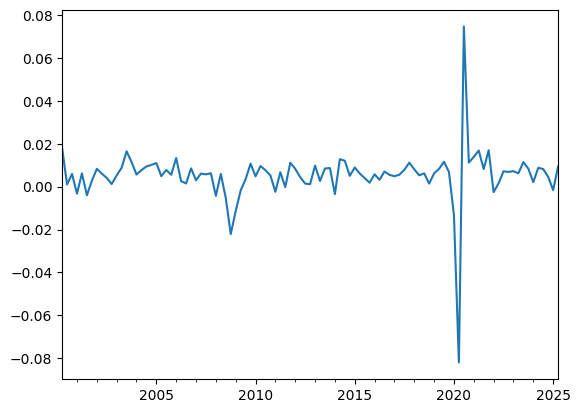

In [22]:
GDP = data['GDPC1']
#GDP.plot()
logret_GDP = np.log(GDP).diff().dropna()
logret_GDP.plot()

pp = PhillipsPerron(logret_GDP)
print(pp.summary().as_text())
# p value = 0 -> stationary

     Phillips-Perron Test (Z-tau)    
Test Statistic                -14.065
P-value                         0.000
Lags                               16
-------------------------------------

Trend: Constant
Critical Values: -3.45 (1%), -2.87 (5%), -2.57 (10%)
Null Hypothesis: The process contains a unit root.
Alternative Hypothesis: The process is weakly stationary.


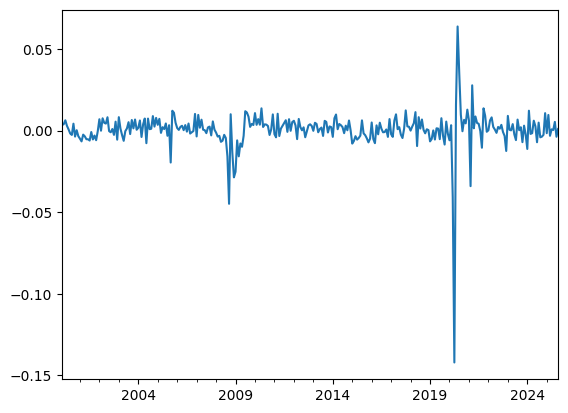

In [24]:
INDPRO = data['INDPRO']
#INDPRO.plot()

logret_INDPRO = np.log(INDPRO).diff().dropna()
logret_INDPRO.plot()

pp = PhillipsPerron(logret_INDPRO)
print(pp.summary().as_text())
# p value = 0 -> stazionaria

     Phillips-Perron Test (Z-tau)    
Test Statistic                -15.261
P-value                         0.000
Lags                               16
-------------------------------------

Trend: Constant
Critical Values: -3.45 (1%), -2.87 (5%), -2.57 (10%)
Null Hypothesis: The process contains a unit root.
Alternative Hypothesis: The process is weakly stationary.


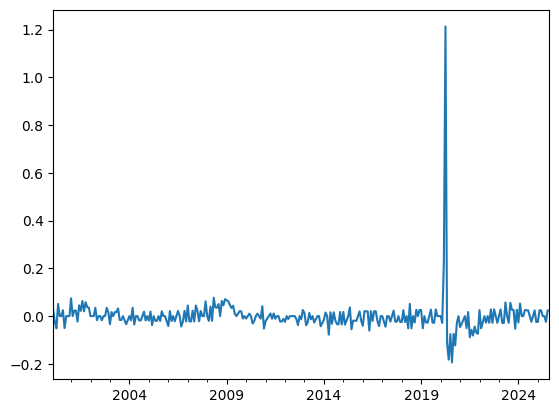

In [45]:
UNRATE = data['UNRATE']
#UNRATE.plot()

logret_UNRATE = np.log(UNRATE).diff().dropna()
logret_UNRATE.plot()

pp = PhillipsPerron(logret_UNRATE)
print(pp.summary().as_text())
# p value = 0 -> stazionaria

     Phillips-Perron Test (Z-tau)    
Test Statistic                -10.575
P-value                         0.000
Lags                               16
-------------------------------------

Trend: Constant
Critical Values: -3.45 (1%), -2.87 (5%), -2.57 (10%)
Null Hypothesis: The process contains a unit root.
Alternative Hypothesis: The process is weakly stationary.


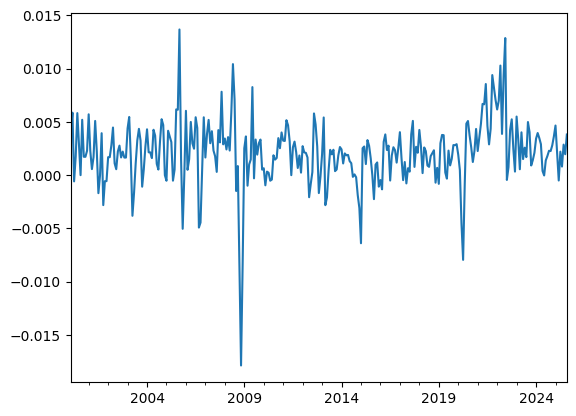

In [26]:
CPI = data['CPIAUCSL']
#CPI.plot()

logret_CPI = np.log(CPI).diff().dropna()
logret_CPI.plot()

pp = PhillipsPerron(logret_CPI)
print(pp.summary().as_text())
# p value = 0 -> stazionaria

     Phillips-Perron Test (Z-tau)    
Test Statistic                -12.296
P-value                         0.000
Lags                               16
-------------------------------------

Trend: Constant
Critical Values: -3.45 (1%), -2.87 (5%), -2.57 (10%)
Null Hypothesis: The process contains a unit root.
Alternative Hypothesis: The process is weakly stationary.


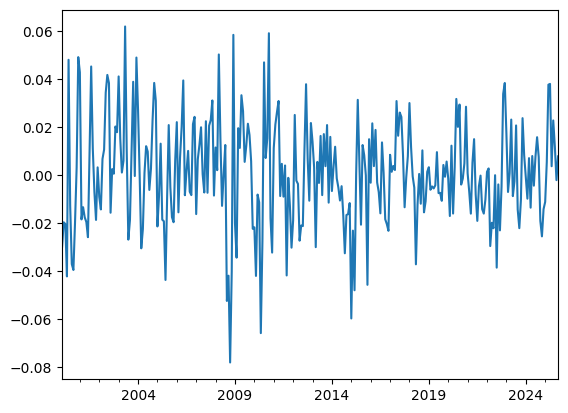

In [27]:
USDEUR = data['EXUSEU']

logret_USDEUR = np.log(USDEUR).diff().dropna()
logret_USDEUR.plot()

pp = PhillipsPerron(logret_USDEUR)
print(pp.summary().as_text())
# p value = 0 -> stazionaria

     Phillips-Perron Test (Z-tau)    
Test Statistic                -92.552
P-value                         0.000
Lags                               34
-------------------------------------

Trend: Constant
Critical Values: -3.43 (1%), -2.86 (5%), -2.57 (10%)
Null Hypothesis: The process contains a unit root.
Alternative Hypothesis: The process is weakly stationary.


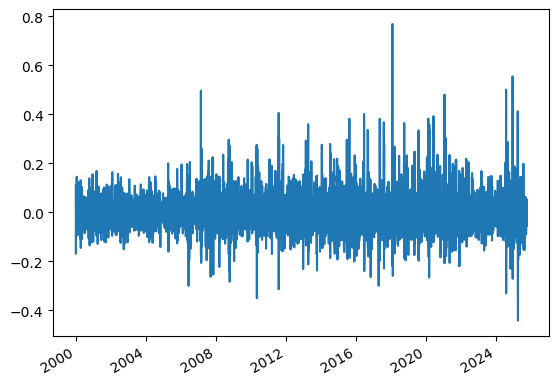

In [28]:
VIX = data['VIXCLS']

logret_VIX = np.log(VIX).diff().dropna()
logret_VIX.plot()

pp = PhillipsPerron(logret_VIX)
print(pp.summary().as_text())
# p value = 0 -> stazionaria

     Phillips-Perron Test (Z-tau)    
Test Statistic                -11.177
P-value                         0.000
Lags                               16
-------------------------------------

Trend: Constant
Critical Values: -3.45 (1%), -2.87 (5%), -2.57 (10%)
Null Hypothesis: The process contains a unit root.
Alternative Hypothesis: The process is weakly stationary.


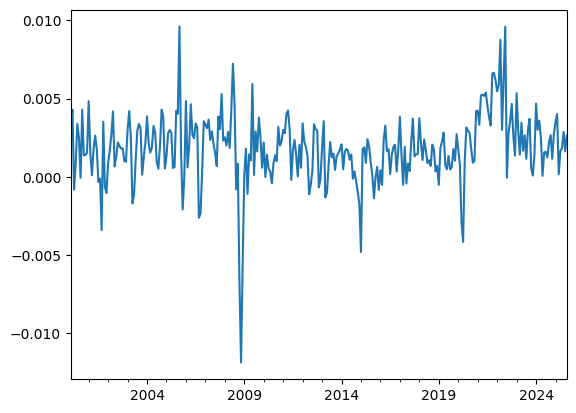

In [29]:
PCE = data['PCEPI']
#PCE.plot()

logret_PCE = np.log(PCE).diff().dropna()
logret_PCE.plot()

pp = PhillipsPerron(logret_PCE)
print(pp.summary().as_text())
# p value = 0 -> stazionaria

     Phillips-Perron Test (Z-tau)    
Test Statistic                -20.600
P-value                         0.000
Lags                               16
-------------------------------------

Trend: Constant
Critical Values: -3.45 (1%), -2.87 (5%), -2.57 (10%)
Null Hypothesis: The process contains a unit root.
Alternative Hypothesis: The process is weakly stationary.


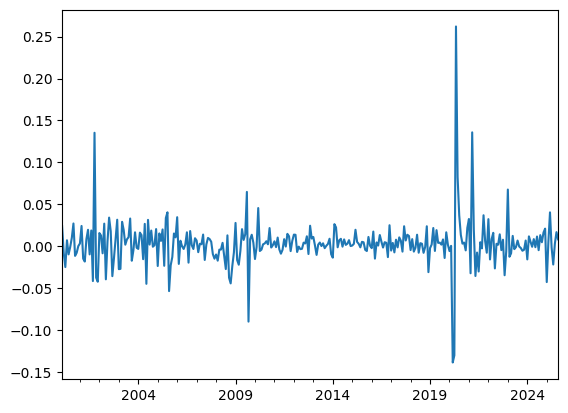

In [30]:
DG = data['PCEDG']

logret_DG = np.log(DG).diff().dropna()
logret_DG.plot()

pp = PhillipsPerron(logret_DG)
print(pp.summary().as_text())
# p value = 0 -> stazionaria

In [31]:
tickers = ['DX-Y.NYB', '^RUT', '^GSPC']

data_yf = yf.download(tickers, start='2000-01-01')
data_yf.head()


/tmp/ipython-input-223108897.py:3: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data_yf = yf.download(tickers, start='2000-01-01')
[*********************100%***********************]  3 of 3 completed


Price            Close                                 High               \
Ticker        DX-Y.NYB        ^GSPC        ^RUT    DX-Y.NYB        ^GSPC   
Date                                                                       
2000-01-03  100.220001  1455.219971  496.420013  101.830002  1478.000000   
2000-01-04  100.410004  1399.420044  478.380005  100.860001  1455.219971   
2000-01-05  100.379997  1402.109985  478.829987  100.470001  1413.270020   
2000-01-06  100.650002  1403.449951  475.339996  100.809998  1411.900024   
2000-01-07  100.800003  1441.469971  488.309998  100.930000  1441.469971   

Price                          Low                                 Open  \
Ticker            ^RUT    DX-Y.NYB        ^GSPC        ^RUT    DX-Y.NYB   
Date                                                                      
2000-01-03  510.959991  100.190002  1438.359985  489.950012  101.669998   
2000-01-04  497.049988  100.010002  1397.430054  478.200012  100.550003   
2000-01-05  479.480011   99.709999  1377.680054  467.559998  100.419998   
2000-01-06  480.190002   99.809998  1392.099976  474.399994  100.309998   
2000-01-07  488.309998  100.440002  1400.729980  475.339996  100.489998   

Price                                 Volume                              
Ticker            ^GSPC        ^RUT DX-Y.NYB         ^GSPC          ^RUT  
Date                                                                      
2000-01-03  1469.250000  504.760010      0.0  9.318000e+08  9.318000e+08  
2000-01-04  1455.219971  497.049988      0.0  1.009000e+09  1.009000e+09  
2000-01-05  1399.420044  478.380005      0.0  1.085500e+09  1.085500e+09  
2000-01-06  1402.109985  478.829987      0.0  1.092300e+09  1.092300e+09  
2000-01-07  1403.449951  475.339996      0.0  1.225200e+09  1.225200e+09

In [32]:
Close = data_yf['Close']
DXY = Close['DX-Y.NYB']
SP500 = Close['^GSPC']
RU2000 = Close['^RUT']

     Phillips-Perron Test (Z-tau)    
Test Statistic                -80.680
P-value                         0.000
Lags                               35
-------------------------------------

Trend: Constant
Critical Values: -3.43 (1%), -2.86 (5%), -2.57 (10%)
Null Hypothesis: The process contains a unit root.
Alternative Hypothesis: The process is weakly stationary.


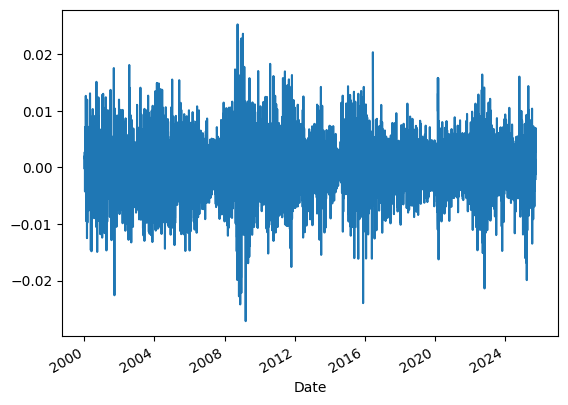

In [33]:
logret_DXY = np.log(DXY).diff().dropna()
logret_DXY.plot()

pp = PhillipsPerron(logret_DXY)
print(pp.summary().as_text())
# p value = 0 -> stazionaria

     Phillips-Perron Test (Z-tau)    
Test Statistic                -89.649
P-value                         0.000
Lags                               35
-------------------------------------

Trend: Constant
Critical Values: -3.43 (1%), -2.86 (5%), -2.57 (10%)
Null Hypothesis: The process contains a unit root.
Alternative Hypothesis: The process is weakly stationary.


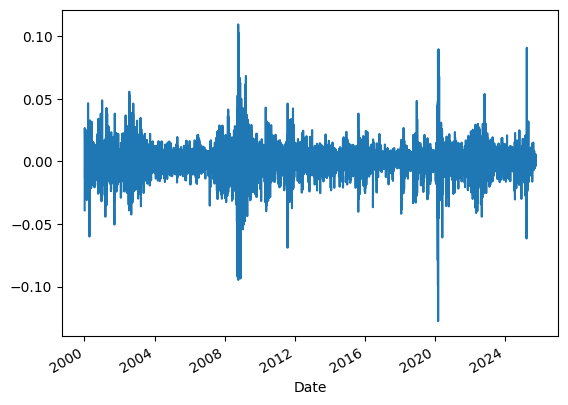

In [34]:
logret_SP500 = np.log(SP500).diff().dropna()
logret_SP500.plot()

pp = PhillipsPerron(logret_SP500)
print(pp.summary().as_text())
# p value = 0 -> stazionaria

     Phillips-Perron Test (Z-tau)    
Test Statistic                -86.860
P-value                         0.000
Lags                               35
-------------------------------------

Trend: Constant
Critical Values: -3.43 (1%), -2.86 (5%), -2.57 (10%)
Null Hypothesis: The process contains a unit root.
Alternative Hypothesis: The process is weakly stationary.


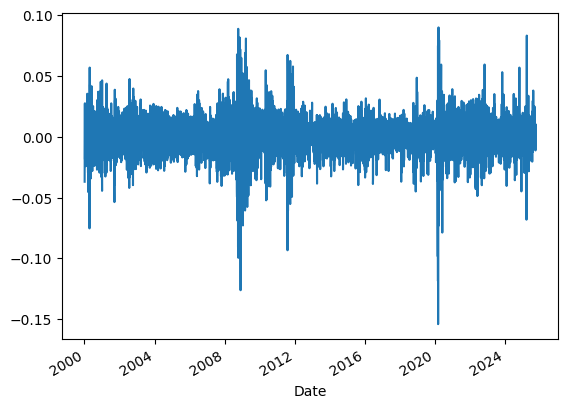

In [35]:
logret_RU2000 = np.log(RU2000).diff().dropna()
logret_RU2000.plot()

pp = PhillipsPerron(logret_RU2000)
print(pp.summary().as_text())
# p value = 0 -> stazionaria

In [80]:
logret_GDP.name= 'logr GDP'
logret_INDPRO.name= 'logr INDPRO'
logret_UNRATE.name= 'logr UNEMP'
logret_CPI.name= 'logr CPI'
logret_USDEUR.name= 'logr USDEUR'
logret_VIX.name= 'logr VIX'
logret_PCE.name= 'logr PCE'
logret_DG.name= 'logr PCE:DG'
logret_DXY.name= 'logr DXY'
logret_SP500.name= 'logr SP'
logret_RU2000.name= 'logr RU2000'

df = pd.concat(
    [
        logret_GDP.resample('QE').sum(),
        logret_INDPRO.resample('QE').sum(),
        logret_UNRATE.resample('QE').sum(),
        logret_CPI.resample('QE').sum(),
        logret_USDEUR.resample('QE').sum(),
        logret_VIX.resample('QE').sum(),
        logret_PCE.resample('QE').sum(),
        logret_DG.resample('QE').sum(),
        logret_DXY.resample('QE').sum(),
        logret_SP500.resample('QE').sum(),
        logret_RU2000.resample('QE').sum()
    ],
    axis=1
)




In [81]:
df.index = df.index.to_period('Q').strftime('Q%q-%Y')

In [82]:
dataset = df.iloc[1:-2]
dataset

,logr GDP,logr INDPRO,logr UNEMP,logr CPI,logr USDEUR,logr VIX,logr PCE,logr PCE:DG,logr DXY,logr SP,logr RU2000
Q2-2000,0.018049,0.009929,0.000000,0.006993,-0.014414,-0.231946,0.003382,-0.027561,0.013190,-0.029787,-0.041395
Q3-2000,0.001019,-0.000205,-0.025318,0.008097,-0.089070,-0.136324,0.006729,0.036189,0.058265,0.003475,0.019083
Q4-2000,0.005953,-0.006874,0.000000,0.005744,0.032586,0.288190,0.004287,-0.019298,-0.033125,-0.098944,-0.105399
Q1-2001,-0.003283,-0.014037,0.097638,0.008554,0.011071,-0.184870,0.006469,0.012618,0.068859,-0.117755,-0.069634
Q2-2001,0.006226,-0.014128,0.045462,0.009045,-0.062815,-0.487315,0.006150,0.009682,0.017399,0.053730,0.129149
...,...,...,...,...,...,...,...,...,...,...,...
Q2-2024,0.008816,0.007142,0.050010,0.003276,-0.009892,-0.092822,0.004064,0.006561,0.012546,0.038480,-0.036848
Q3-2024,0.008214,-0.006393,0.000000,0.005478,0.031191,0.296286,0.005046,0.019974,-0.049272,0.053831,0.085276
Q4-2024,0.004588,0.004370,0.000000,0.008703,-0.058600,0.004662,0.006542,0.042020,0.073718,0.020466,0.000085
Q1-2025,-0.001626,0.004803,0.024098,0.006315,0.032044,0.217214,0.007668,0.002655,-0.040250,-0.031422,-0.080527


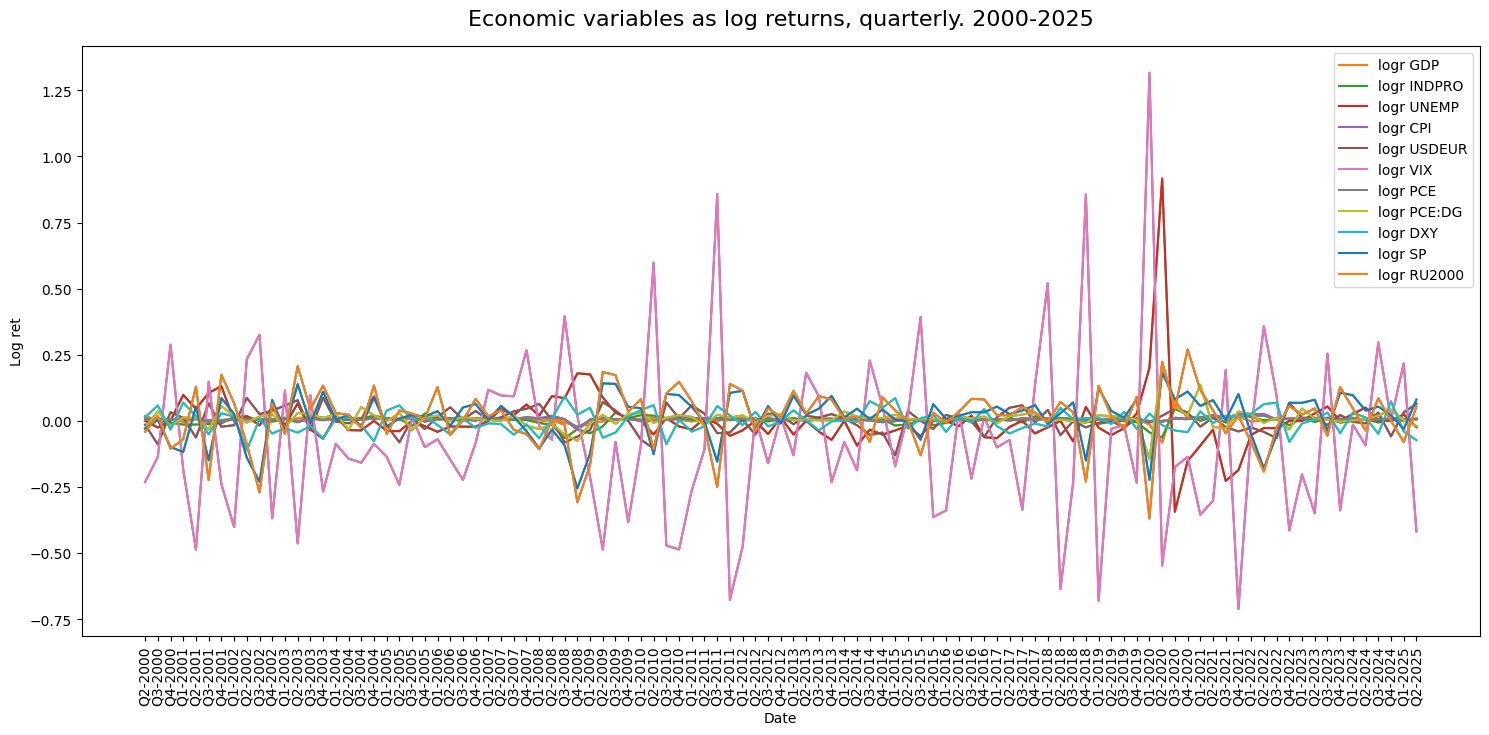

In [92]:
plt.figure(figsize=(15, 7))
plt.plot(dataset)

for col in dataset.columns:
    plt.plot(dataset.index, dataset[col], label=str(col))

plt.title("Economic variables as log returns, quarterly. 2000-2025", fontsize=16, pad=15)
plt.xlabel("Date")
plt.ylabel("Log ret")
plt.legend()
plt.tight_layout()
plt.xticks(rotation=90)

plt.savefig("macro_logret_quarterly.png", dpi=300, bbox_inches='tight')

plt.show()

Now we can download the dataset and the figure



In [65]:
from google.colab import files


In [85]:
dataset.to_csv("dataset_macro_logret.csv")

files.download("dataset_macro_logret.csv")

dataset.to_excel("dataset_macro_logret.xlsx")
files.download("dataset_macro_logret.xlsx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [93]:
files.download("macro_logret_quarterly.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

That's it for this notebook